In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
sns.set_theme(style="whitegrid")

CWD = Path.cwd()
BASE_DIR = CWD.parent if CWD.name == "analysis" else CWD
RESULT_DIR = BASE_DIR / "results"
FIG_DIR = RESULT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load Step 4.3 findings and evaluation tables
with open(RESULT_DIR / "step04_03_MODEL_EVALUATION_FINDINGS.json", "r", encoding="utf-8") as f:
    s43 = json.load(f)

overall_df = pd.read_csv(RESULT_DIR / "step04_03_model_comparison_overall.csv")
severity_df = pd.read_csv(RESULT_DIR / "step04_03_test_performance_by_severity.csv")
stop_type_df = pd.read_csv(RESULT_DIR / "step04_03_test_performance_by_stop_type.csv")
train_cat_df = pd.read_csv(RESULT_DIR / "step04_03_test_performance_by_train_category.csv")
tuning_df = pd.read_csv(RESULT_DIR / "step04_03_hyperparameter_tuning_log.csv")

print("Loaded Step 4.3 evaluation artifacts successfully.")

Loaded Step 4.3 evaluation artifacts successfully.


In [4]:
# Enrich stratified tables (severity, stop_context, primary_type_code) using exact column names:
# model, MAE, RMSE, R2, Median_AE, Mean_Bias
def enrich_with_mse_and_baseline(df: pd.DataFrame, group_col: str) -> pd.DataFrame:
    out = df.copy()
    out["MSE"] = np.round(out["RMSE"] ** 2, 4)

    base = (
        out[out["model"] == "1_Persistence_Baseline"][[group_col, "MAE", "RMSE", "MSE", "R2"]]
        .rename(columns={
            "MAE": "_base_mae",
            "RMSE": "_base_rmse",
            "MSE": "_base_mse",
            "R2": "_base_r2",
        })
    )
    out = out.merge(base, on=group_col, how="left")

    out["MAE_gain_vs_persistence_pct"] = np.round((out["_base_mae"] - out["MAE"]) * 100.0 / out["_base_mae"], 2)
    out["RMSE_gain_vs_persistence_pct"] = np.round((out["_base_rmse"] - out["RMSE"]) * 100.0 / out["_base_rmse"], 2)
    out["MSE_gain_vs_persistence_pct"] = np.round((out["_base_mse"] - out["MSE"]) * 100.0 / out["_base_mse"], 2)
    out["R2_gain_vs_persistence"] = np.round(out["R2"] - out["_base_r2"], 6)

    return out.drop(columns=["_base_mae", "_base_rmse", "_base_mse", "_base_r2"])

# 1. Enrich hyperparameter tuning log with train_sample_MSE and val_MSE
tuning_eval = tuning_df.copy()
tuning_eval["train_sample_MSE"] = np.round(tuning_eval["train_sample_RMSE"] ** 2, 4)
tuning_eval["val_MSE"] = np.round(tuning_eval["val_RMSE"] ** 2, 4)

# 2. Enrich overall_model_comparison (columns: model, selected_config, train_MAE, train_RMSE, train_R2, val_MAE, val_RMSE, val_R2, test_MAE, test_RMSE, test_R2, ...)
overall_eval = overall_df.copy()
overall_eval["train_MSE"] = np.round(overall_eval["train_RMSE"] ** 2, 4)
overall_eval["val_MSE"] = np.round(overall_eval["val_RMSE"] ** 2, 4)
overall_eval["test_MSE"] = np.round(overall_eval["test_RMSE"] ** 2, 4)

base_row = overall_eval[overall_eval["model"] == "1_Persistence_Baseline"].iloc[0]
overall_eval["val_MAE_gain_vs_persistence_pct"] = np.round(
    (base_row["val_MAE"] - overall_eval["val_MAE"]) * 100.0 / base_row["val_MAE"], 2
)
overall_eval["val_RMSE_gain_vs_persistence_pct"] = np.round(
    (base_row["val_RMSE"] - overall_eval["val_RMSE"]) * 100.0 / base_row["val_RMSE"], 2
)
overall_eval["val_MSE_gain_vs_persistence_pct"] = np.round(
    (base_row["val_MSE"] - overall_eval["val_MSE"]) * 100.0 / base_row["val_MSE"], 2
)
overall_eval["test_MSE_gain_vs_persistence_pct"] = np.round(
    (base_row["test_MSE"] - overall_eval["test_MSE"]) * 100.0 / base_row["test_MSE"], 2
)
overall_eval["test_R2_gain_vs_persistence"] = np.round(
    overall_eval["test_R2"] - base_row["test_R2"], 6
)

# 3. Enrich stratified tables using their exact group columns
severity_eval = enrich_with_mse_and_baseline(severity_df, "target_severity")
stop_type_eval = enrich_with_mse_and_baseline(stop_type_df, "stop_context")
train_cat_eval = enrich_with_mse_and_baseline(train_cat_df, "primary_type_code")

# Save enriched Step 5.1 CSV artifacts
overall_eval.to_csv(RESULT_DIR / "step05_01_overall_mse_rmse_mae_r2.csv", index=False)
severity_eval.to_csv(RESULT_DIR / "step05_01_severity_mse_evaluation.csv", index=False)
stop_type_eval.to_csv(RESULT_DIR / "step05_01_stop_context_mse_evaluation.csv", index=False)
train_cat_eval.to_csv(RESULT_DIR / "step05_01_train_category_mse_evaluation.csv", index=False)

print("=== STEP 5.1 OVERALL INDEPENDENT MODEL EVALUATION (WITH MSE) ===")
print(overall_eval.to_string(index=False))
print("\n=== STEP 5.1 SEVERITY REGIME EVALUATION (WITH MSE) ===")
print(severity_eval.to_string(index=False))
print("\n=== STEP 5.1 STOP CONTEXT EVALUATION (INTERMEDIATE VS TERMINAL) ===")
print(stop_type_eval.to_string(index=False))

=== STEP 5.1 OVERALL INDEPENDENT MODEL EVALUATION (WITH MSE) ===
                 model     selected_config  train_MAE  train_RMSE  train_R2  val_MAE  val_RMSE   val_R2  test_MAE  test_RMSE  test_R2  test_Median_AE  test_Mean_Bias  test_MAE_gain_vs_persistence_pct  test_RMSE_gain_vs_persistence_pct  train_MSE  val_MSE  test_MSE  val_MAE_gain_vs_persistence_pct  val_RMSE_gain_vs_persistence_pct  val_MSE_gain_vs_persistence_pct  test_MSE_gain_vs_persistence_pct  test_R2_gain_vs_persistence
1_Persistence_Baseline identity_curr_delay     7.5882     18.3577  0.919518   8.4207   20.3487 0.935176    8.2098    20.2024 0.910606          3.0000         -1.2145                              0.00                               0.00   337.0051 414.0696  408.1370                             0.00                              0.00                             0.00                              0.00                     0.000000
   2_Linear_Regression  Ridge (alpha=10.0)     6.5345     15.8046  0.940347   7

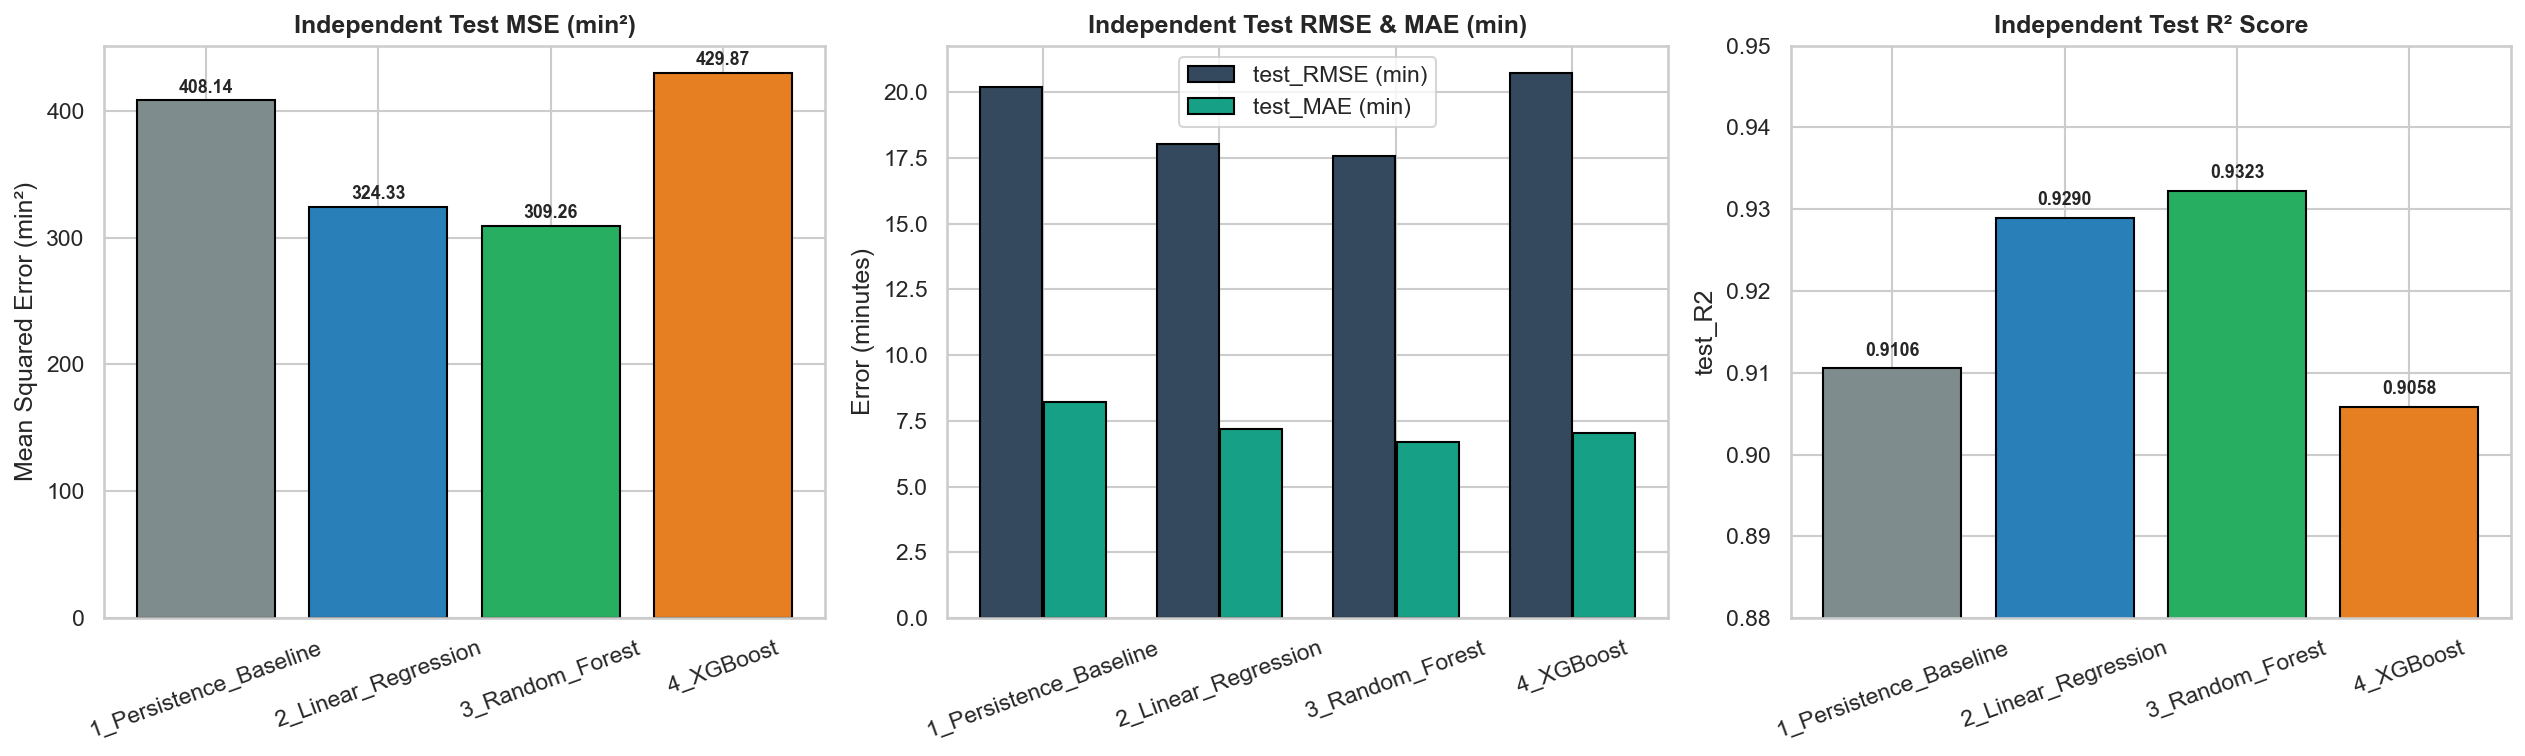

Saved Step 5.1 findings to: D:\M_Tech_CSE_AI\SEM01\DWDM\project\indian_railway_delay\results\step05_01_MODEL_EVALUATION_FINDINGS.json


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

models = overall_eval["model"].tolist()
test_mse = overall_eval["test_MSE"].tolist()
test_rmse = overall_eval["test_RMSE"].tolist()
test_mae = overall_eval["test_MAE"].tolist()
test_r2 = overall_eval["test_R2"].tolist()

palette = ["#7f8c8d", "#2980b9", "#27ae60", "#e67e22"]

# Panel 1: Test MSE (min^2)
bars1 = axes[0].bar(models, test_mse, color=palette, edgecolor="black")
axes[0].set_title("Independent Test MSE (min²)", fontweight="bold")
axes[0].set_ylabel("Mean Squared Error (min²)")
axes[0].tick_params(axis="x", rotation=20)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 6, f"{b.get_height():.2f}", ha="center", fontsize=8.5, fontweight="bold")

# Panel 2: Test RMSE vs MAE (min)
x = np.arange(len(models))
axes[1].bar(x - 0.18, test_rmse, width=0.35, label="test_RMSE (min)", color="#34495e", edgecolor="black")
axes[1].bar(x + 0.18, test_mae, width=0.35, label="test_MAE (min)", color="#16a085", edgecolor="black")
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=20)
axes[1].set_title("Independent Test RMSE & MAE (min)", fontweight="bold")
axes[1].set_ylabel("Error (minutes)")
axes[1].legend()

# Panel 3: Test R^2
bars3 = axes[2].bar(models, test_r2, color=palette, edgecolor="black")
axes[2].set_ylim(0.88, 0.95)
axes[2].set_title("Independent Test R² Score", fontweight="bold")
axes[2].set_ylabel("test_R2")
axes[2].tick_params(axis="x", rotation=20)
for b in bars3:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + 0.0015, f"{b.get_height():.4f}", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
fig_path = FIG_DIR / "step05_01_independent_model_evaluation.png"
plt.savefig(fig_path, dpi=150)
plt.show()

step05_01_findings = {
    "step": "step05_01_independent_model_evaluation",
    "evaluation_scope": s43.get("evaluation_scope", {}),
    "chronological_periods": {
        "training": {"start": "2025-02-08", "end": "2025-11-26", "days": 292, "eligible_observed_transitions": 26528080},
        "validation": {"start": "2025-11-27", "end": "2026-01-01", "days": 36, "eligible_observed_transitions": 3278765},
        "testing": {"start": "2026-01-02", "end": "2026-02-07", "days": 37, "eligible_observed_transitions": 3351989},
    },
    "hyperparameter_tuning_with_mse": tuning_eval.to_dict(orient="records"),
    "overall_evaluation_with_mse": overall_eval.to_dict(orient="records"),
    "severity_evaluation_with_mse": severity_eval.to_dict(orient="records"),
    "stop_context_evaluation_with_mse": stop_type_eval.to_dict(orient="records"),
    "train_category_evaluation_with_mse": train_cat_eval.to_dict(orient="records"),
    "residual_accuracy_bands": s43.get("test_residual_diagnostics", {}),
}

out_json = RESULT_DIR / "step05_01_MODEL_EVALUATION_FINDINGS.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(step05_01_findings, f, indent=2)

print(f"Saved Step 5.1 findings to: {out_json}")